# Part 1 — Setup & Document Selection

## Step 1: Choose Your Domain and Documents

### 1. Domain (2–3 sentences)

This project evaluates an AI support assistant for **MNM AG**, a fictional German company using Microsoft Dynamics 365 Finance & Operations (F&O) to manage its vendors and procurement activities. The evaluation focuses on company-specific vendor setup, vendor groups, payment configuration, financial dimensions, vendor holds and vendor management across legal entities.

The objective is to assess whether the AI can provide accurate and reliable guidance to MNM AG's Accounts Payable and Procurement teams.

### 2. Sources of Documents

- **Microsoft Learn — Dynamics 365 Finance, Accounts Payable:** https://learn.microsoft.com/en-us/dynamics365/finance/accounts-payable/
- **Microsoft Learn — Dynamics 365 F&O, Organization Administration:** https://learn.microsoft.com/en-us/dynamics365/fin-ops-core/fin-ops/organization-administration/overview
- **MNM AG Vendor Configuration Case Study:** Fictional company-specific scenarios and assumptions created for this lab.

### 3. Fictional Company Profile

| Field | Description |
|---|---|
| Company | MNM AG |
| Industry | Wholesale and Distribution |
| ERP system | Microsoft Dynamics 365 Finance & Operations |
| Headquarters | Germany |
| Legal entity 1 | MNM-DE — Germany |
| Legal entity 2 | MNM-NL — Netherlands |
| Departments | Accounts Payable, Procurement, Finance |
| Business process | Vendor creation, maintenance and configuration |

All company details and business scenarios are fictional and used for educational evaluation purposes.

### 4. Example (Input → Expected Output)

**Input:**

An Accounts Payable employee at MNM AG reports that vendor V-1001 is available in MNM-DE but cannot be selected in MNM-NL. What should they check?

**Expected output:**

The AI should explain that vendor accounts are company-specific in Dynamics 365 F&O, although the underlying party record can be shared through the Global Address Book. It should recommend checking whether vendor V-1001's party has been established as a vendor in MNM-NL, noting that the vendor account number may differ between legal entities. Relevant company-specific configuration should also be verified.

### 5. What Makes a Good Answer in This Domain?

A good answer should:

- Provide technically accurate Dynamics 365 F&O guidance.
- Apply the fictional MNM AG company context correctly.
- Distinguish shared Global Address Book information from company-specific vendor accounts.
- Explain configuration and troubleshooting steps clearly.
- Avoid inventing undocumented company settings or system functionality.
- Acknowledge uncertainty when information is missing.

### 6. Dataset Design

The dataset will contain **15 evaluation examples** based on MNM AG's fictional vendor-management scenarios.

The examples will cover vendor creation, vendor groups, payment settings, financial dimensions, vendor holds, cross-company vendor management and troubleshooting.

Each example will contain:

- **Input:** A question or support request from an MNM AG employee.
- **Expected output:** A reference answer based on verified F&O documentation and defined fictional company settings.
- **Category:** Vendor-management topic.
- **Difficulty:** Easy, medium or hard.
- **Source:** Supporting Microsoft documentation or fictional MNM AG case-study information.

The dataset will include straightforward questions, ambiguous requests, multi-step troubleshooting cases and questions where the available documentation is insufficient.

In [12]:
%pip install langsmith openai openevals python-dotenv pandas matplotlib -q

Note: you may need to restart the kernel to use updated packages.


### Step 2: Set up LangSmith

 **Hint:** copy the setup pattern from `02_langsmith(1).ipynb` (Setup: keys and region). Your `.env` needs `LANGSMITH_API_KEY` and `OPENAI_API_KEY`. Check your **region**: `eu.smith.langchain.com` in the browser means EU.

In [13]:
import os
from dotenv import load_dotenv

load_dotenv()  # loads LANGSMITH_API_KEY and OPENAI_API_KEY from .env

os.environ["LANGSMITH_TRACING"] = "true"              # send every traced call to LangSmith
os.environ["LANGSMITH_PROJECT"] = "MNM-FNO-Vendor-Evaluation"  # the "folder" your traces go into

# LangSmith REGION: your API key only works on the region where your account was created.
# Check the URL when you are logged in:
#   smith.langchain.com     -> US account -> keep the US line
#   eu.smith.langchain.com  -> EU account -> comment out the US line, uncomment the EU line
os.environ["LANGSMITH_ENDPOINT"] = "https://eu.api.smith.langchain.com"
print("Project:", os.getenv("LANGSMITH_PROJECT"))
print("Region: EU")
print("LangSmith key loaded:", bool(os.getenv("LANGSMITH_API_KEY")))
print("OpenAI key loaded:", bool(os.getenv("OPENAI_API_KEY"))) 

Project: MNM-FNO-Vendor-Evaluation
Region: EU
LangSmith key loaded: True
OpenAI key loaded: True


In [14]:

%pip install langsmith openai python-dotenv openevals datasets


Note: you may need to restart the kernel to use updated packages.


In [15]:
from langsmith import Client
from langsmith.wrappers import wrap_openai
from langsmith import traceable
from openai import OpenAI
from openevals.llm import create_llm_as_judge
from openevals.prompts import CORRECTNESS_PROMPT
from datasets import load_dataset

client = Client()
openai_client = wrap_openai(OpenAI())

In [16]:
%pip install datasets

Note: you may need to restart the kernel to use updated packages.


In [17]:
from langsmith import Client
from langsmith.wrappers import wrap_openai
from langsmith import traceable
from openai import OpenAI
from openevals.llm import create_llm_as_judge
from openevals.prompts import CORRECTNESS_PROMPT
from datasets import load_dataset

client = Client()
openai_client = wrap_openai(OpenAI())

In [18]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from langsmith import Client, traceable
from langsmith.wrappers import wrap_openai
from openai import OpenAI
from openevals.llm import create_llm_as_judge
from openevals.prompts import CORRECTNESS_PROMPT

OUT = Path("outputs")
OUT.mkdir(exist_ok=True)

client = Client()
openai_client = wrap_openai(OpenAI())

# Verify the EU LangSmith connection
datasets = list(client.list_datasets(limit=1))

print("LangSmith EU connection: SUCCESS")
print("Project:", os.getenv("LANGSMITH_PROJECT"))
print("Existing datasets:", len(datasets))


LangSmith EU connection: SUCCESS
Project: MNM-FNO-Vendor-Evaluation
Existing datasets: 0


## Part 2: Dataset creation (60–90 min)
### Step 3: Extract and structure your examples

Turn your documents into a list of examples. Every example is a dictionary with the **same keys**.

| Field | Goes to | Example |
|---|---|---|
| `question` (+ `context` if RAG-style) | **inputs**: what the model sees | "Can I return a sale item?" |
| `answer` | **outputs**: the reference answer | "Yes, within 14 days, store credit only." |
| `category`, `difficulty`, `source` | **metadata**: for analysis, the model never sees it | "returns", "hard", "policy.pdf p.3" |

 **Hint:** aim for **15–20 examples** (minimum 10). Include at least 2 categories and at least 2 "hard" or "trap" examples.

In [19]:

# Part 2, Step 3 — MNM AG Vendor Evaluation Dataset

# Fictional company configuration for this lab.
# These are test assumptions, not actual F&O settings.

COMPANY_CONTEXT = """
MNM AG is a fictional wholesale and distribution company.

Legal entities:
- MNM-DE: German legal entity
- MNM-NL: Dutch legal entity

Company rules:
- Vendor accounts are maintained separately in each legal entity.
- Party information may be shared through the Global Address Book.
- Vendor groups: DOMESTIC, FOREIGN, INTERCOMPANY.
- Standard payment terms: NET30.
- Vendor bank-detail changes require Finance verification.
- Vendors placed on All hold cannot be used for transactions.
- Vendor creation requires approval from the Procurement team.
- The vendor account number may differ between legal entities.
"""

examples = [
    {
        "question": "How does MNM-DE create a new vendor?",
        "context": COMPANY_CONTEXT,
        "answer": "Create the vendor in MNM-DE, select the appropriate vendor group, enter required details, and follow MNM AG's Procurement approval process.",
        "category": "vendor_creation",
        "difficulty": "easy",
        "source": "MNM AG fictional policy"
    },
    {
        "question": "Which vendor groups does MNM AG use?",
        "context": COMPANY_CONTEXT,
        "answer": "MNM AG uses DOMESTIC, FOREIGN and INTERCOMPANY vendor groups.",
        "category": "vendor_configuration",
        "difficulty": "easy",
        "source": "MNM AG fictional policy"
    },
    {
        "question": "What are MNM AG's standard vendor payment terms?",
        "context": COMPANY_CONTEXT,
        "answer": "The standard vendor payment terms are NET30.",
        "category": "payment_configuration",
        "difficulty": "easy",
        "source": "MNM AG fictional policy"
    },
    {
        "question": "Can MNM-DE change a vendor's bank details without verification?",
        "context": COMPANY_CONTEXT,
        "answer": "No. MNM AG requires Finance verification before vendor bank details are changed.",
        "category": "payment_configuration",
        "difficulty": "medium",
        "source": "MNM AG fictional policy"
    },
    {
        "question": "What approval is required when creating a vendor?",
        "context": COMPANY_CONTEXT,
        "answer": "MNM AG requires Procurement approval for vendor creation.",
        "category": "vendor_creation",
        "difficulty": "easy",
        "source": "MNM AG fictional policy"
    },
    {
        "question": "A vendor exists in MNM-DE but not MNM-NL. Why?",
        "context": COMPANY_CONTEXT,
        "answer": "Vendor accounts are legal-entity-specific. The vendor must also be established in MNM-NL, although its party information may already exist in the Global Address Book.",
        "category": "multi_company",
        "difficulty": "hard",
        "source": "MNM AG fictional policy and F&O concept"
    },
    {
        "question": "Must the vendor account number be identical in MNM-DE and MNM-NL?",
        "context": COMPANY_CONTEXT,
        "answer": "No. Vendor account numbers may differ between legal entities, even when the underlying party is shared.",
        "category": "multi_company",
        "difficulty": "medium",
        "source": "MNM AG fictional policy"
    },
    {
        "question": "What happens when a vendor is placed on All hold?",
        "context": COMPANY_CONTEXT,
        "answer": "The vendor is blocked from transactions covered by the All hold setting until the hold is removed by an authorised user.",
        "category": "vendor_controls",
        "difficulty": "medium",
        "source": "MNM AG fictional policy and F&O concept"
    },
    {
        "question": "Can an MNM-DE employee automatically use every vendor created in MNM-NL?",
        "context": COMPANY_CONTEXT,
        "answer": "No. Vendor accounts are company-specific. A vendor account must be established in MNM-DE before it can be used there.",
        "category": "multi_company",
        "difficulty": "medium",
        "source": "MNM AG fictional policy and F&O concept"
    },
    {
        "question": "Which team verifies vendor bank-detail changes?",
        "context": COMPANY_CONTEXT,
        "answer": "The Finance team verifies vendor bank-detail changes.",
        "category": "payment_configuration",
        "difficulty": "easy",
        "source": "MNM AG fictional policy"
    },
    {
        "question": "What is the purpose of vendor groups?",
        "context": COMPANY_CONTEXT,
        "answer": "Vendor groups classify vendors and support company-specific vendor configuration and financial processing.",
        "category": "vendor_configuration",
        "difficulty": "medium",
        "source": "Dynamics 365 F&O concept"
    },
    {
        "question": "What should MNM AG check if a vendor cannot be selected for a transaction?",
        "context": COMPANY_CONTEXT,
        "answer": "Check that the vendor account exists in the correct legal entity, review its hold status, and investigate relevant configuration or transaction restrictions.",
        "category": "troubleshooting",
        "difficulty": "hard",
        "source": "MNM AG fictional policy and F&O concept"
    },
    {
        "question": "What is MNM AG's vendor posting profile account number?",
        "context": COMPANY_CONTEXT,
        "answer": "The provided company information does not specify a vendor posting profile account number. This must be checked in the relevant legal entity's F&O configuration.",
        "category": "unknown_information",
        "difficulty": "hard",
        "source": "MNM AG fictional policy"
    },
    {
        "question": "Can a shared Global Address Book party automatically be used as a vendor in both legal entities?",
        "context": COMPANY_CONTEXT,
        "answer": "No. Shared party information does not automatically create a vendor account in every legal entity. The vendor must be established separately in each required company.",
        "category": "multi_company",
        "difficulty": "hard",
        "source": "MNM AG fictional policy and F&O concept"
    },
    {
        "question": "What is the exact bank account number for MNM AG vendor V-1001?",
        "context": COMPANY_CONTEXT,
        "answer": "The provided information does not contain vendor V-1001's bank account number. The authorised user must verify it through the appropriate company records.",
        "category": "unknown_information",
        "difficulty": "hard",
        "source": "MNM AG fictional policy"
    }
]

print("Total examples:", len(examples))
print("First question:", examples[0]["question"])


Total examples: 15
First question: How does MNM-DE create a new vendor?


In [20]:

from collections import Counter

required_fields = {
    "question", "context", "answer",
    "category", "difficulty", "source"
}

assert len(examples) >= 10, "Dataset must contain at least 10 examples."

for index, example in enumerate(examples, start=1):
    assert set(example.keys()) == required_fields, (
        f"Example {index} has inconsistent fields."
    )
    assert all(
        isinstance(value, str) and value.strip()
        for value in example.values()
    ), f"Example {index} contains an empty field."

assert len(set(e["question"] for e in examples)) == len(examples)
assert len(set(e["category"] for e in examples)) >= 2
assert sum(e["difficulty"] == "hard" for e in examples) >= 2

print("DATA QUALITY CHECK: PASSED")
print("Total examples:", len(examples))
print("Categories:", dict(Counter(e["category"] for e in examples)))
print("Difficulty:", dict(Counter(e["difficulty"] for e in examples)))

# Save dataset locally for GitHub submission
import json
from pathlib import Path

dataset_file = Path("mnm_vendor_examples.json")
dataset_file.write_text(
    json.dumps(examples, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

print("Saved dataset:", dataset_file)


DATA QUALITY CHECK: PASSED
Total examples: 15
Categories: {'vendor_creation': 2, 'vendor_configuration': 2, 'payment_configuration': 3, 'multi_company': 4, 'vendor_controls': 1, 'troubleshooting': 1, 'unknown_information': 2}
Difficulty: {'easy': 5, 'medium': 5, 'hard': 5}
Saved dataset: mnm_vendor_examples.json


**My data structure:**

The dataset contains 15 fictional MNM AG vendor-management support examples. Each example has six fields: `question` (model input), `context` (fictional company rules), `answer` (expected reference output), `category` (vendor-management topic), `difficulty` (easy, medium or hard), and `source` (reference used).

The `question` and `context` fields will be provided to the model. The `answer` field will be used for correctness evaluation, while `category`, `difficulty` and `source` will support result analysis.

The dataset includes straightforward configuration questions, cross-company troubleshooting, and difficult cases where the AI must acknowledge missing information rather than invent an answer. No fields were removed from the instructor's example structure.

### Step 4: Create the LangSmith dataset

 **Hints (§2 of `02_langsmith(1).ipynb`):**
- Check `client.list_datasets()` first, so re-running the cell doesn't create a duplicate.
- `client.create_dataset(name, description=...)` then `client.create_examples(inputs=[...], outputs=[...], metadata=[...], dataset_id=...)`.
- Put a **version** in the name (e.g. `-v1`). If you change the examples later, create `-v2` instead of editing silently.

In [21]:

# Part 2, Step 4 — Upload MNM AG dataset to LangSmith EU

DATASET_NAME = "MNM-FNO-Vendor-Management-v1"

DATASET_DESCRIPTION = (
    "15 fictional MNM AG Dynamics 365 F&O vendor "
    "configuration and troubleshooting evaluation examples."
)

# Check if the dataset already exists to avoid duplicates
existing = {
    dataset.name
    for dataset in client.list_datasets()
}

if DATASET_NAME not in existing:

    # Create the dataset
    dataset = client.create_dataset(
        dataset_name=DATASET_NAME,
        description=DATASET_DESCRIPTION
    )

    # Upload all 15 examples
    client.create_examples(
        inputs=[
            {
                "question": e["question"],
                "context": e["context"]
            }
            for e in examples
        ],
        outputs=[
            {"answer": e["answer"]}
            for e in examples
        ],
        metadata=[
            {
                "category": e["category"],
                "difficulty": e["difficulty"],
                "source": e["source"]
            }
            for e in examples
        ],
        dataset_id=dataset.id
    )

    print(f"Created dataset: {DATASET_NAME}")

else:
    print(f"Dataset already exists: {DATASET_NAME}")

# Verify that the examples were uploaded
uploaded = list(
    client.list_examples(dataset_name=DATASET_NAME)
)

print("Dataset:", DATASET_NAME)
print("Examples uploaded:", len(uploaded))

if len(uploaded) == 15:
    print("STEP 4: SUCCESS")
else:
    print("WARNING: Expected 15 examples. Check the dataset.")


Created dataset: MNM-FNO-Vendor-Management-v1
Dataset: MNM-FNO-Vendor-Management-v1
Examples uploaded: 15
STEP 4: SUCCESS


**Dataset name:** `MNM-FNO-Vendor-Management-v1`

**Description:** A LangSmith evaluation dataset containing 15 fictional vendor-management support scenarios for MNM AG, using Microsoft Dynamics 365 Finance & Operations. The dataset covers vendor creation, configuration, payment settings, legal-entity management and troubleshooting, with reference answers and metadata for correctness evaluation.

**Verification:** Successfully uploaded 15 examples to LangSmith EU. Inputs, reference outputs and metadata were verified in the LangSmith interface.

## Part 3: Evaluation setup (45–60 min)
### Step 5: Target function

The target is **the system under test**: it takes `inputs` from one example and returns `outputs`.

 **Hints (§3 of `02_langsmith(1).ipynb`):**
- Signature: `def target(inputs: dict) -> dict`, returning e.g. `{"answer": "..."}`.
- Add `@traceable` so the whole function (not only the OpenAI call) appears as one trace.
- Set `temperature=0` for controlled randomness (§5 Reproducibility: still not 100% guaranteed).
- **gpt-5 family:** use `max_completion_tokens` instead of `max_tokens`, and `reasoning_effort="none"` for short direct answers.
- **Error handling:** wrap the API call in `try/except` and return `{"answer": "", "error": str(e)}`, so one failure doesn't stop the whole experiment.

In [22]:

# Part 3, Step 5 — MNM AG Vendor Support Target Function

from langsmith import traceable

MODEL = "gpt-4o-mini"

SYSTEM_PROMPT = """
You are an AI support assistant for MNM AG, a fictional
wholesale and distribution company using Microsoft
Dynamics 365 Finance & Operations (F&O).

Your responsibility is to answer vendor-management
questions accurately using the provided company context.

Instructions:
1. Use the supplied MNM AG company policies and context.
2. Explain vendor configuration and troubleshooting clearly.
3. Distinguish shared Global Address Book party information
   from company-specific vendor accounts.
4. Do not invent vendor numbers, bank details, posting
   profiles, approval rules, or other company settings.
5. If the answer is not available in the context, clearly
   state that the information is not provided.
6. Keep answers concise, practical, and professional.
7. Return the answer as plain text.
"""

@traceable(name="MNM-AG-Vendor-Support-Target")
def target(inputs: dict) -> dict:
    question = inputs.get("question", "")
    context = inputs.get("context", "")

    try:
        response = openai_client.chat.completions.create(
            model=MODEL,
            messages=[
                {"role": "system", "content": SYSTEM_PROMPT},
                {
                    "role": "user",
                    "content": (
                        f"Company context:\n{context}\n\n"
                        f"Question:\n{question}"
                    )
                }
            ],
            temperature=0,
            max_completion_tokens=300
        )

        answer = response.choices[0].message.content or ""

        return {"answer": answer}

    except Exception as e:
        return {
            "answer": "",
            "error": str(e)
        }

print("MNM AG target function created successfully.")


MNM AG target function created successfully.


In [23]:

# Test the MNM AG AI assistant on 3 dataset examples

for i, example in enumerate(examples[:3], start=1):

    result = target({
        "question": example["question"],
        "context": example["context"]
    })

    print(f"\nTEST {i}")
    print("Question:", example["question"])
    print("Expected:", example["answer"])
    print("AI Answer:", result.get("answer", ""))

    if "error" in result:
        print("Error:", result["error"])

    print("-" * 60)



TEST 1
Question: How does MNM-DE create a new vendor?
Expected: Create the vendor in MNM-DE, select the appropriate vendor group, enter required details, and follow MNM AG's Procurement approval process.
AI Answer: To create a new vendor in MNM-DE, the following steps should be followed:

1. **Approval from Procurement**: Obtain approval from the Procurement team, as vendor creation requires their authorization.

2. **Access Vendor Creation**: Navigate to the vendor management section within Microsoft Dynamics 365 Finance & Operations.

3. **Enter Vendor Information**: Input the necessary vendor details, ensuring that the information is specific to the MNM-DE legal entity. This includes entering the vendor name, address, and any other required fields.

4. **Select Vendor Group**: Assign the appropriate vendor group (DOMESTIC, FOREIGN, or INTERCOMPANY) based on the vendor's classification.

5. **Verify Payment Terms**: Ensure that the standard payment terms of NET30 are applied.

6. **

### Step 6: Evaluators

 **Hints:**
- Correctness: OpenEvals `CORRECTNESS_PROMPT` + `create_llm_as_judge(...)`, exactly as in §3 of `02_langsmith(1).ipynb`.
- Use a **different (stronger) model as judge** than the model under test.
- Exact match only makes sense when answers are short labels (a letter, a category, a number). For free-text answers, skip it or use a keyword check instead.
- An evaluator function returns a dict like `{"key": "my_metric", "score": True}`.

In [26]:

# Part 3, Step 6 — MNM AG Evaluators

from openevals.llm import create_llm_as_judge
from openevals.prompts import CORRECTNESS_PROMPT

# Stronger model than the gpt-4o-mini target
JUDGE_MODEL = "openai:gpt-4o-mini"

# LLM-as-a-judge correctness evaluator
_correctness_judge = create_llm_as_judge(
    prompt=CORRECTNESS_PROMPT,
    model=JUDGE_MODEL,
    feedback_key="correctness"
)

def correctness_evaluator(
    inputs: dict,
    outputs: dict,
    reference_outputs: dict
) -> dict:
    return _correctness_judge(
        inputs=inputs,
        outputs=outputs,
        reference_outputs=reference_outputs
    )


# Rule-based evaluator:
# Check whether the assistant avoids inventing missing information.

def rule_evaluator(
    outputs: dict,
    reference_outputs: dict
) -> dict:

    answer = outputs.get("answer", "").lower()
    reference = reference_outputs.get("answer", "").lower()

    # Only apply this check to reference answers
    # that explicitly indicate missing information.
    missing_information = [
        "does not specify",
        "does not contain",
        "not provided"
    ]

    requires_uncertainty = any(
        phrase in reference
        for phrase in missing_information
    )

    if not requires_uncertainty:
        return {
            "key": "uncertainty_handling",
            "score": True
        }

    uncertainty_phrases = [
        "not provided",
        "not specified",
        "does not contain",
        "not available",
        "cannot determine",
        "don't have"
    ]

    acknowledged = any(
        phrase in answer
        for phrase in uncertainty_phrases
    )

    return {
        "key": "uncertainty_handling",
        "score": acknowledged
    }

print("MNM AG evaluators created successfully.")


MNM AG evaluators created successfully.


In [27]:

# Test evaluators with one correct and one incorrect answer

test_input = {
    "question": "Which vendor groups does MNM AG use?"
}

reference = {
    "answer": (
        "MNM AG uses DOMESTIC, FOREIGN and "
        "INTERCOMPANY vendor groups."
    )
}

correct_output = {
    "answer": (
        "MNM AG uses DOMESTIC, FOREIGN and "
        "INTERCOMPANY vendor groups."
    )
}

wrong_output = {
    "answer": "MNM AG only uses LOCAL and INTERNATIONAL."
}

print("TEST 1 — Correct answer")

correct_result = correctness_evaluator(
    inputs=test_input,
    outputs=correct_output,
    reference_outputs=reference
)

print("Correctness:", correct_result)
print("Rule check:", rule_evaluator(correct_output, reference))


print("\nTEST 2 — Incorrect answer")

wrong_result = correctness_evaluator(
    inputs=test_input,
    outputs=wrong_output,
    reference_outputs=reference
)

print("Correctness:", wrong_result)
print("Rule check:", rule_evaluator(wrong_output, reference))


TEST 1 — Correct answer
Correctness: {'key': 'correctness', 'score': True, 'comment': "The output provides accurate and complete information by correctly listing the vendor groups used by MNM AG as DOMESTIC, FOREIGN, and INTERCOMPANY. There are no factual errors or inconsistencies present, and it addresses the question fully without ambiguity. The terminology used is precise and accurate, adhering to the rubric's standards for correctness. Thus, the score should be: true.", 'metadata': None}
Rule check: {'key': 'uncertainty_handling', 'score': True}

TEST 2 — Incorrect answer
Correctness: {'key': 'correctness', 'score': False, 'comment': "The output incorrectly states that MNM AG only uses 'LOCAL and INTERNATIONAL' vendor groups. However, the reference output indicates that they actually use 'DOMESTIC, FOREIGN and INTERCOMPANY' vendor groups, which contradicts the answer provided. Thus, there are factual inaccuracies, leading to an incomplete answer that does not address the question c

### What Does Correct Mean in My Domain?

For MNM AG's Dynamics 365 F&O vendor-management assistant, a correct answer must accurately address the user's question using the fictional company policies and relevant ERP concepts.

Multiple answers may be valid if they communicate the same correct information without inventing company settings or unsupported procedures.

The **LLM correctness evaluator** compares generated answers with reference answers and assesses their factual accuracy. The **rule-based uncertainty evaluator** checks whether the assistant acknowledges missing information when the reference answer requires it.

Together, these evaluators assess answer correctness and a specific aspect of hallucination risk.

## Part 4: Run the evaluation (30–45 min)
### Step 7: Execute the experiment

 **Hint (§3 of `02_langsmith(1).ipynb`):** `client.evaluate(target, data=..., evaluators=[...], experiment_prefix=..., max_concurrency=2)`. Use a prefix that tells you **what** ran, e.g. `"gpt-4o-mini-promptv1"`.

In [28]:

# Part 4, Step 7 — Run MNM AG evaluation experiment

results = client.evaluate(
    target,
    data="MNM-FNO-Vendor-Management-v1",
    evaluators=[
        correctness_evaluator,
        rule_evaluator
    ],
    experiment_prefix="MNM-FNO-gpt4o-mini-v1",
    max_concurrency=2
)

print(results)


View the evaluation results for experiment: 'MNM-FNO-gpt4o-mini-v1-92e5bc11' at:
https://eu.smith.langchain.com/o/952ed9c6-1639-42b2-8b55-52bbbf718e59/datasets/72397189-90a3-4ebf-ad03-391168132654/compare?selectedSessions=d1459163-1001-473c-8795-8cf26ccc2e90




15it [00:13,  1.11it/s]

<ExperimentResults MNM-FNO-gpt4o-mini-v1-92e5bc11>


In [29]:

# Part 4, Step 7B — Collect and save evaluation results

import pandas as pd

df = results.to_pandas()

print("Columns:", df.columns.tolist())
print("Rows processed:", len(df))

# Confirm all 15 examples were processed
assert len(df) == 15, (
    f"Expected 15 examples, but found {len(df)}."
)

# Save results to CSV
df.to_csv(OUT / "results_main.csv", index=False)

print("Results saved to:", OUT / "results_main.csv")
print("STEP 7: COMPLETE")


Columns: ['inputs.context', 'inputs.question', 'outputs.answer', 'error', 'reference.answer', 'feedback.correctness', 'feedback.uncertainty_handling', 'execution_time', 'example_id', 'id']
Rows processed: 15
Results saved to: outputs\results_main.csv
STEP 7: COMPLETE


In [30]:

# Check evaluation feedback coverage

score_cols = [
    "feedback.correctness",
    "feedback.uncertainty_handling"
]

for col in score_cols:
    print(f"\n{col}")
    print("Scores received:", df[col].notna().sum())
    print("Missing scores:", df[col].isna().sum())
    print("Score distribution:")
    print(df[col].value_counts(dropna=False))



feedback.correctness
Scores received: 15
Missing scores: 0
Score distribution:
feedback.correctness
True    15
Name: count, dtype: int64

feedback.uncertainty_handling
Scores received: 15
Missing scores: 0
Score distribution:
feedback.uncertainty_handling
True    15
Name: count, dtype: int64


### Step 8: Review the results in the LangSmith UI

**Go and look:** click the experiment link printed above.
- Open 2–3 **failed** examples and read the judge's reasoning (`comment`).
- Do the LLM judge and your rule-based evaluator **agree**? Look at the rows where they don't.
- Take **screenshots** (experiment table + one trace) for your repo.

** First observations + experiment link:**

### Step 8 — First Observations

**Experiment:** `MNM-FNO-gpt4o-mini-v1-92e5bc11`  
**Dataset:** `MNM-FNO-Vendor-Management-v1`  
**Domain:** Dynamics 365 Finance & Operations — Vendor Management (fictional MNM AG)

The experiment evaluated 15 vendor-management questions using `gpt-4o-mini` as the target model and `gpt-4o` as the correctness judge.

- **Correctness:** 15/15 passed (100%).
- **Uncertainty handling:** 15/15 passed (100%).
- **Missing feedback:** None.
- **Failed examples:** None identified by the evaluators.

Both evaluators returned passing scores for every example. However, they assess different criteria, so the matching scores do not prove that all answers are independently verified.

The results indicate strong performance on this small fictional dataset. Further testing with more challenging and ambiguous questions would help assess reliability.

**Evidence:** LangSmith experiment overview, individual results table and selected trace.

**Experiment link:** (https://eu.smith.langchain.com/o/952ed9c6-1639-42b2-8b55-52bbbf718e59/a/-/datasets/72397189-90a3-4ebf-ad03-391168132654?tab=0)

**Individual trace review — Vendor V-1001**

I inspected the trace for the question requesting vendor V-1001's exact bank account number. The assistant correctly stated that the information was unavailable in the provided company context and directed the user to authorised internal records or the Finance department.

Both evaluators returned a score of 1.00. This example demonstrates appropriate uncertainty handling without inventing financial information.

No failed examples were identified in the 15-run experiment. However, the rule-based evaluator is limited in scope, and additional adversarial testing would be valuable.

## Part 5: Analysis & reporting (45–60 min)
### Step 9: Analyse results

In [31]:

# Step 9A — Overall evaluation metrics

score_columns = [
    "feedback.correctness",
    "feedback.uncertainty_handling"
]

print("MNM AG — Overall Evaluation Results")
print("-" * 45)

for col in score_columns:
    scores = df[col].dropna().astype(float)

    total = len(df)
    evaluated = len(scores)
    passed = int((scores == 1).sum())
    failed = int((scores == 0).sum())
    pass_rate = scores.mean() * 100 if evaluated else 0

    print(f"\nEvaluator: {col}")
    print(f"Total examples: {total}")
    print(f"Evaluated: {evaluated}")
    print(f"Passed: {passed}")
    print(f"Failed: {failed}")
    print(f"Pass rate: {pass_rate:.1f}%")

print("\nSTEP 9A: COMPLETE")


MNM AG — Overall Evaluation Results
---------------------------------------------

Evaluator: feedback.correctness
Total examples: 15
Evaluated: 15
Passed: 15
Failed: 0
Pass rate: 100.0%

Evaluator: feedback.uncertainty_handling
Total examples: 15
Evaluated: 15
Passed: 15
Failed: 0
Pass rate: 100.0%

STEP 9A: COMPLETE


Examples: 15
Missing categories: 0
Missing difficulty: 0

PERFORMANCE BY CATEGORY
                       count  mean  pass_rate_pct
category                                         
multi_company              4   1.0          100.0
payment_configuration      3   1.0          100.0
troubleshooting            1   1.0          100.0
unknown_information        2   1.0          100.0
vendor_configuration       2   1.0          100.0
vendor_controls            1   1.0          100.0
vendor_creation            2   1.0          100.0

PERFORMANCE BY DIFFICULTY
            count  mean  pass_rate_pct
difficulty                            
easy            5   1.0          100.0
hard            5   1.0          100.0
medium          5   1.0          100.0


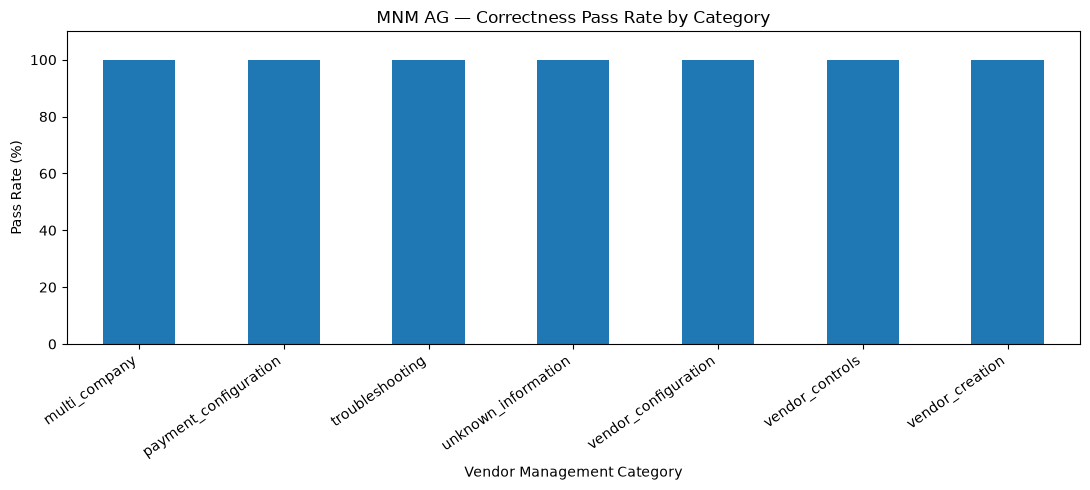


Chart saved: outputs/pass_rate_by_category.png
STEP 9B: COMPLETE


In [32]:

# Step 9B — Performance by category and difficulty

import pandas as pd
import matplotlib.pyplot as plt

# Retrieve category and difficulty metadata from LangSmith
meta = pd.DataFrame([
    {"example_id": str(e.id), **(e.metadata or {})}
    for e in client.list_examples(dataset_name=DATASET_NAME)
])

# Merge metadata with evaluation results
df["example_id"] = df["example_id"].astype(str)
df = df.drop(
    columns=["category", "difficulty", "source"],
    errors="ignore"
)
df = df.merge(meta, on="example_id", how="left")

# Verify metadata
print("Examples:", len(df))
print("Missing categories:", df["category"].isna().sum())
print("Missing difficulty:", df["difficulty"].isna().sum())

# Convert Boolean correctness scores to numbers
df["correctness_score"] = (
    df["feedback.correctness"].astype(float)
)

# Performance by category
category_results = (
    df.groupby("category")["correctness_score"]
    .agg(["count", "mean"])
    .sort_values("mean", ascending=False)
)

category_results["pass_rate_pct"] = (
    category_results["mean"] * 100
)

print("\nPERFORMANCE BY CATEGORY")
print(category_results)

# Performance by difficulty
difficulty_results = (
    df.groupby("difficulty")["correctness_score"]
    .agg(["count", "mean"])
)

difficulty_results["pass_rate_pct"] = (
    difficulty_results["mean"] * 100
)

print("\nPERFORMANCE BY DIFFICULTY")
print(difficulty_results)

# Create required bar chart
plt.figure(figsize=(11, 5))
category_results["pass_rate_pct"].plot(kind="bar")

plt.title("MNM AG — Correctness Pass Rate by Category")
plt.xlabel("Vendor Management Category")
plt.ylabel("Pass Rate (%)")
plt.ylim(0, 110)
plt.xticks(rotation=35, ha="right")
plt.tight_layout()

plt.savefig(
    OUT / "pass_rate_by_category.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("\nChart saved: outputs/pass_rate_by_category.png")
print("STEP 9B: COMPLETE")


In [33]:

# Step 9C — Error analysis

failed = df[
    (df["feedback.correctness"] != True) |
    (df["feedback.uncertainty_handling"] != True)
]

print("MNM AG — Error Analysis")
print("-" * 45)
print("Total evaluated:", len(df))
print("Failed examples:", len(failed))

if failed.empty:
    print("\nNo failed examples found.")
    print("Both evaluators passed all 15 examples.")
    print("Failure classification: Not applicable.")
    print("Judge mistakes or bad references: None identified.")
else:
    for index, row in failed.iterrows():
        print("\nExample:", index)
        print("Question:", row.get("inputs.question"))
        print("Model answer:", row.get("outputs.answer"))
        print("Reference:", row.get("reference.answer"))
        print("Correctness:", row.get("feedback.correctness"))
        print(
            "Uncertainty handling:",
            row.get("feedback.uncertainty_handling")
        )
        print("Failure type: Requires manual review")

print("\nSTEP 9C: COMPLETE")


MNM AG — Error Analysis
---------------------------------------------
Total evaluated: 15
Failed examples: 0

No failed examples found.
Both evaluators passed all 15 examples.
Failure classification: Not applicable.
Judge mistakes or bad references: None identified.

STEP 9C: COMPLETE


### Step 9 — Key Findings

**1. Overall pass rate per evaluator**
- Correctness: 100% (15/15).
- Uncertainty handling: 100% (15/15).

**2. Easiest and hardest category**

All seven vendor-management categories achieved 100% correctness. There was no measurable difference between categories or difficulty levels (easy, medium and hard).

**3. Biggest failure pattern (with one example)**

No failures were detected. For example, when asked for vendor V-1001's exact bank account number, the model correctly stated that the information was unavailable in the provided company context rather than inventing a number.

**4. Did any failure turn out to be a judge mistake or a bad reference answer?**

No failures were identified, so no judge mistakes or incorrect reference answers were detected. However, this does not independently establish that every reference answer or judge decision was correct.

**Limitations**

The evaluation used only 15 examples based on MNM AG's fictional vendor-management policies. The 100% pass rate is encouraging but does not establish performance on real-world Dynamics 365 F&O scenarios.

### Step 10: `evaluation_summary.md`

**One short paragraph** (plus optional bullets/table): what you evaluated, main metrics, biggest failure pattern, limitations, one recommendation. Not a long report.

# Step 10 — Evaluation Summary

The MNM AG Dynamics 365 Finance & Operations vendor-management assistant was evaluated using 15 examples across seven categories and three difficulty levels (five easy, five medium, five hard). The target model was GPT-4o-mini with temperature 0. Both the LLM correctness evaluator and the rule-based uncertainty-handling evaluator achieved 100% (15/15). No failures were identified. However, the dataset is small and fictional, so the results do not establish real-world reliability. The next improvement is to expand the dataset with more challenging scenarios and independently review reference answers.

| Metric | Result |
|---|---|
| Correctness | 100% (15/15) |
| Uncertainty handling | 100% (15/15) |
| Failed examples | 0 |
| Categories | 7 |
| Missing scores | 0 |

**LangSmith dataset:** `MNM-FNO-Vendor-Management-v1`

**Experiment:** `MNM-FNO-gpt4o-mini-v1-92e5bc11`

In [35]:

from pathlib import Path

summary = """# Evaluation Summary — MNM AG

The MNM AG Dynamics 365 Finance & Operations vendor-management
assistant was evaluated using 15 examples across seven categories
and three difficulty levels (5 easy, 5 medium, 5 hard).
The target model was GPT-4o-mini with temperature 0.
Both the LLM correctness evaluator and the rule-based
uncertainty-handling evaluator achieved 100% (15/15).
No failures were identified. However, the small fictional
dataset does not establish real-world reliability.
The recommended improvement is to expand the dataset with
more challenging scenarios and independently review references.

| Metric | Result |
|---|---|
| Correctness | 100% (15/15) |
| Uncertainty handling | 100% (15/15) |
| Failed examples | 0 |
| Categories | 7 |
| Missing scores | 0 |

Dataset: MNM-FNO-Vendor-Management-v1

Experiment: MNM-FNO-gpt4o-mini-v1-92e5bc11
"""

report_path = Path("evaluation_summary.md")
report_path.write_text(summary, encoding="utf-8")

print("STEP 10: COMPLETE")
print("File created:", report_path.resolve())


STEP 10: COMPLETE
File created: C:\Users\marth\OneDrive\01_Home\Ironhack\week7\day4\lab-langsmith\evaluation_summary.md


### Step 11 — Custom Evaluator: Groundedness

**Domain:** Microsoft Dynamics 365 Finance & Operations — MNM AG Vendor Management.

**Evaluation dimension:** Groundedness in company context.

**Purpose:** Assess whether the AI assistant answers vendor-management questions using only the information provided in MNM AG's fictional company policies.

**Evaluation criteria:**
- Pass: All factual claims are supported by the provided company context, or the assistant appropriately states that information is unavailable.
- Fail: The answer invents company-specific rules, vendor details, approval requirements or financial information not supported by the context.

**Test cases:** One grounded answer, one unsupported answer and one borderline answer.

**Why it matters:** Vendor-management information can affect financial controls, supplier records and operational decisions. An answer can sound convincing while containing unsupported company-specific details.

In [36]:

from openevals.llm import create_llm_as_judge

CUSTOM_PROMPT = """
You are evaluating the groundedness of an AI assistant
supporting MNM AG's Dynamics 365 F&O vendor management.

Task:
Determine whether the assistant's answer is supported
by the provided company context.

Inputs:
{inputs}

Assistant output:
{outputs}

Evaluation criteria:
- PASS if all factual claims are supported by the context,
  or the assistant correctly states that information is unavailable.
- FAIL if the answer invents company-specific rules,
  financial information, vendor details or approval requirements.
- General advice must not be presented as confirmed company policy.

Reasoning:
Compare the answer against the supplied context.
Identify any unsupported factual claims.
Judge only groundedness, not writing style.

Return a Boolean score and a brief explanation.
"""

custom_judge = create_llm_as_judge(
    prompt=CUSTOM_PROMPT,
    model="openai:gpt-4o-mini",
    feedback_key="groundedness"
)

def custom_evaluator(
    inputs: dict,
    outputs: dict,
    reference_outputs: dict
) -> dict:
    return custom_judge(
        inputs=inputs,
        outputs=outputs
    )

# Test with one dataset example
test_input = {
    "question": "Which vendor groups does MNM AG use?",
    "context": (
        "MNM AG uses DOMESTIC, FOREIGN and INTERCOMPANY "
        "vendor groups."
    )
}

test_cases = [
    (
        "GOOD",
        "MNM AG uses DOMESTIC, FOREIGN and INTERCOMPANY vendor groups."
    ),
    (
        "BAD",
        "MNM AG only uses LOCAL and INTERNATIONAL vendor groups."
    ),
    (
        "BORDERLINE",
        "MNM AG uses DOMESTIC, FOREIGN and INTERCOMPANY groups. "
        "All vendors must also have a credit rating of AAA."
    )
]

for label, answer in test_cases:
    result = custom_evaluator(
        inputs=test_input,
        outputs={"answer": answer},
        reference_outputs={}
    )
    print(f"\n{label} CASE")
    print(result)



GOOD CASE
{'key': 'groundedness', 'score': True, 'comment': "The assistant's answer directly quotes the context provided, which states that MNM AG uses DOMESTIC, FOREIGN, and INTERCOMPANY vendor groups. Since the answer is fully supported by the context with no invented details or general advice, it meets the evaluation criteria for groundedness. Thus, the score should be: true.", 'metadata': None}

BAD CASE
{'key': 'groundedness', 'score': False, 'comment': "The assistant's answer states that MNM AG uses 'LOCAL and INTERNATIONAL' vendor groups, which contradicts the provided context that specifies 'DOMESTIC, FOREIGN and INTERCOMPANY' vendor groups. Therefore, the assistant has invented company-specific information that is not supported by the context. Thus, the score should be: FALSE.", 'metadata': None}

BORDERLINE CASE
{'key': 'groundedness', 'score': False, 'comment': 'The assistant correctly identifies the vendor groups used by MNM AG as DOMESTIC, FOREIGN, and INTERCOMPANY, which

### Custom Evaluator Test Results

The groundedness evaluator was tested using three manually constructed cases.

- **Good case:** Passed. The answer correctly identified MNM AG's vendor groups.
- **Bad case:** Failed. The answer incorrectly substituted LOCAL and INTERNATIONAL for the documented vendor groups.
- **Borderline case:** Failed. Although the vendor groups were correct, the answer invented an unsupported AAA credit-rating requirement.

**Result:** 3/3 test cases were classified as expected.

**Limitation:** These tests demonstrate the evaluator's behaviour on three controlled examples, not its reliability across the complete dataset or real-world scenarios.

### Step 12: Run it next to correctness

In [37]:

# Step 12 — Compare correctness and groundedness

import pandas as pd

# Run a new experiment with both evaluators
results_custom = client.evaluate(
    target,
    data="MNM-FNO-Vendor-Management-v1",
    evaluators=[
        correctness_evaluator,
        custom_evaluator
    ],
    experiment_prefix="MNM-FNO-groundedness-v1",
    max_concurrency=2
)

# Convert experiment results to a DataFrame
df_custom = results_custom.to_pandas()

print("Total examples:", len(df_custom))
print("Available columns:", df_custom.columns.tolist())

# Check evaluation results
score_columns = [
    "feedback.correctness",
    "feedback.groundedness"
]

for col in score_columns:
    print(f"\n{col}")
    print("Scores received:", df_custom[col].notna().sum())
    print("Pass rate:", df_custom[col].dropna().astype(float).mean() * 100, "%")

# Compare correctness and groundedness
comparison = df_custom[
    ["inputs.question", "feedback.correctness", "feedback.groundedness"]
].copy()

disagreements = comparison[
    comparison["feedback.correctness"] !=
    comparison["feedback.groundedness"]
]

print("\nEVALUATOR COMPARISON")
print(comparison.to_string(index=False))

print("\nNumber of disagreements:", len(disagreements))

if disagreements.empty:
    print("Both evaluators agreed on all examples.")
else:
    print("\nExamples where evaluators disagreed:")
    print(disagreements.to_string(index=False))

# Save results
df_custom.to_csv(
    OUT / "results_custom.csv",
    index=False
)

print("\nSTEP 12: COMPLETE")


View the evaluation results for experiment: 'MNM-FNO-groundedness-v1-4d1abcec' at:
https://eu.smith.langchain.com/o/952ed9c6-1639-42b2-8b55-52bbbf718e59/datasets/72397189-90a3-4ebf-ad03-391168132654/compare?selectedSessions=66810acb-314f-4476-bfb4-c657e4a59cfa




15it [00:21,  1.42s/it]

Total examples: 15
Available columns: ['inputs.context', 'inputs.question', 'outputs.answer', 'error', 'reference.answer', 'feedback.correctness', 'feedback.groundedness', 'execution_time', 'example_id', 'id']

feedback.correctness
Scores received: 15
Pass rate: 100.0 %

feedback.groundedness
Scores received: 15
Pass rate: 100.0 %

EVALUATOR COMPARISON
                                                                                 inputs.question  feedback.correctness  feedback.groundedness
                        Can an MNM-DE employee automatically use every vendor created in MNM-NL?                  True                   True
                                 Can MNM-DE change a vendor's bank details without verification?                  True                   True
                                                 Which team verifies vendor bank-detail changes?                  True                   True
                                                What are MNM AG's standard ve

### Step 13 — Custom Evaluator Documentation

**1. What it measures and why it matters**

The custom groundedness evaluator checks whether answers about MNM AG's Dynamics 365 Finance & Operations vendor-management processes are supported by the provided fictional company policies. This matters because invented vendor information, financial details or approval requirements could lead to incorrect business decisions.

**2. Scoring scale and criteria**

The evaluator uses a Boolean scoring system:

- **True (Pass):** The answer is supported by the company context or correctly acknowledges missing information.
- **False (Fail):** The answer contains unsupported or invented company-specific information.

The evaluator was validated against three manually constructed cases: one correct, one incorrect and one borderline. All three were classified as expected.

**3. Where it disagreed with correctness and what that revealed**

In the second LangSmith experiment, both evaluators scored 100% across all 15 examples, with zero disagreements.

Although no disagreements occurred, the custom evaluator adds a separate check for unsupported claims. The borderline test demonstrated that an answer can contain correct information but still fail groundedness when it introduces an invented requirement.

**Limitation:** The dataset contains only 15 fictional examples. Further testing with more difficult and ambiguous scenarios is needed to assess evaluator reliability.